In [1]:
from app.graph.workflow import build_graph

c:\Users\DELL\OneDrive\Desktop\hybrid_rag\myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 105/105 [00:00<00:00, 9228.10it/s]


In [2]:
graph = build_graph()

config = {"configurable":{"thread_id":"conversation_001"}}

In [3]:
result1 = graph.invoke(
    {
        "raw_query": "What is the status of order O1012?",
        "role": "support"
    },
    config=config
)

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


In [4]:
print("RAW:", result1["raw_query"])
print("RESOLVED:", result1["query"])
print("ANSWER:", result1["answer"])

RAW: What is the status of order O1012?
RESOLVED: What is the status of order O1012?
ANSWER: Order O1012 has been delivered. It was delivered on July 29, 2026, via BlueDart (Tracking Number: RGD100012).


In [5]:
result2 = graph.invoke(
    {
        "raw_query": "Can it still be returned?",
        "role": "support"
    },
    config=config
)


========== Dense Top 5 ==========
TARGET FOUND
POSITION: 5
ID: DOC002-2026.1-003
SCORE: 0.69495225
RRF SCORE: None
RERANK SCORE: None
SOURCE: dense
SOURCES: None
FILE: return_policy_2026.pdf
SECTION: Return Windows

ALL RESULT IDs:
1 DOC002-2026.1-005
2 DOC002-2026.1-002
3 DOC002-2026.1-004
4 DOC002-2026.1-006
5 DOC002-2026.1-003

========== bm25 top 5 ==========
TARGET NOT FOUND: DOC002-2026.1-003

ALL RESULT IDs:
1 DOC002-2026.1-002
2 DOC001-2026.1-003
3 DOC002-2026.1-009
4 DOC002-2026.1-004
5 DOC002-2026.1-005

========== RRF ==========
TARGET FOUND
POSITION: 7
ID: DOC002-2026.1-003
SCORE: None
RRF SCORE: 0.015384615384615385
RERANK SCORE: None
SOURCE: None
SOURCES: ['dense']
FILE: return_policy_2026.pdf
SECTION: Return Windows

ALL RESULT IDs:
1 DOC002-2026.1-002
2 DOC002-2026.1-005
3 DOC002-2026.1-004
4 DOC001-2026.1-003
5 DOC002-2026.1-009
6 DOC002-2026.1-006
7 DOC002-2026.1-003

========== Authorization_stage ==========
TARGET FOUND
POSITION: 7
ID: DOC002-2026.1-003
SCORE: None

In [ ]:

print("RAW:", result2["raw_query"])
print("RESOLVED:", result2["query"])
print("ROUTE:", result2["route"])

print("SUFFICIENT:", result2.get("sufficient_evidance"))
print("MISSING:", result2.get("missing_information"))
print("NEXT STEP:", result2.get("next_step"))

print("CORRECTIVE RAG QUERY:", result2.get("corrective_rag_query"))
print("CORRECTIVE SQL QUERY:", result2.get("corrective_sql_query"))

print("RETRY COUNT:", result2.get("hybrid_retry_count"))

print("ANSWER:", result2["answer"])

RAW: Can it still be returned?
RESOLVED: Can order O1012 still be returned?
ROUTE: hybrid
SUFFICIENT: None
MISSING: None
NEXT STEP: answer
CORRECTIVE RAG QUERY: None
CORRECTIVE SQL QUERY: None
RETRY COUNT: 2
ANSWER: No, order **O1012** is no longer eligible for a standard return.

* **Product & Delivery Details:** The order contains the **RGD Bag Pro** (category: accessory), which was delivered on **July 29, 2026**.
* **Return Window:** According to company policy, the return window for accessories is **10 calendar days from delivery** [SOURCE_9]. The deadline to return this item was August 8, 2026.
* **Current Status:** As of today (**September 29, 2026**), the item is outside the applicable return window and is not eligible for a standard change-of-mind return [SOURCE_3, SOURCE_9]. 

*(Note: The product has a 6-month warranty, so if there is a confirmed defect, it may be handled under warranty service rather than a standard return [SOURCE_8]).*


In [7]:
from app.graph.state import RagState
from app.graph.nodes import hybrid_corrective_reterieval_node


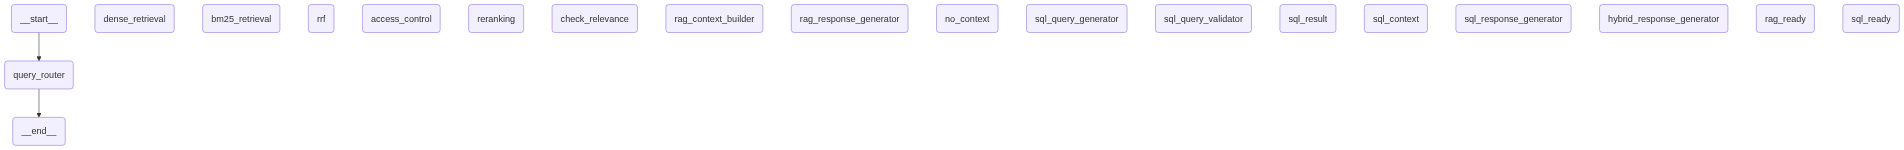

In [11]:
graph